In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
dataset = pd.read_csv('/content/USA_Housing.csv')
X = dataset.iloc[:, 0:1].values
Y = dataset.iloc[:, -1].values
dataset.head()

,Area Income,Area House Age,Area No of Rooms,Area No of Bedrooms,Area Population,Price
0,79545.45857,5.682861,7.009188,4.09,23086.80050,1.059034e+06
1,79248.64245,6.002900,6.730821,3.09,40173.07217,1.505891e+06
2,61287.06718,5.865890,8.512727,5.13,36882.15940,1.058988e+06
3,63345.24005,7.188236,5.586729,3.26,34310.24283,1.260617e+06
4,59982.19723,5.040555,7.839388,4.23,26354.10947,6.309435e+05


In [5]:
print(dataset.columns)
print(dataset.head())

Index(['Area Income', 'Area House Age', 'Area No of Rooms',
       'Area No of Bedrooms', 'Area Population', 'Price'],
      dtype='object')
   Area Income  Area House Age  Area No of Rooms  Area No of Bedrooms  \
0  79545.45857        5.682861          7.009188                 4.09   
1  79248.64245        6.002900          6.730821                 3.09   
2  61287.06718        5.865890          8.512727                 5.13   
3  63345.24005        7.188236          5.586729                 3.26   
4  59982.19723        5.040555          7.839388                 4.23   

   Area Population         Price  
0      23086.80050  1.059034e+06  
1      40173.07217  1.505891e+06  
2      36882.15940  1.058988e+06  
3      34310.24283  1.260617e+06  
4      26354.10947  6.309435e+05  


In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test= train_test_split(X,Y, test_size=0.2, random_state=0)
#random_state=0 is used to get the same random data everytime we run the code

# Simple linear regression

In [ ]:
from sklearn.linear_model import LinearRegression
regressor= LinearRegression()
regressor.fit(X_train, Y_train)  #WE have used fit so that the model can learn from the training data

LinearRegression()

In [ ]:
Y_pred= regressor.predict(X_test)
Y_pred #predicted value

array([1075510.99387527, 1121824.10155187, 1288108.0623983 ,
        844869.12634566,  933916.06204117, 1420912.70044229,
        711979.49700164, 1026088.5790416 , 1708028.61948045,
       1428676.62079602, 1240208.11112218, 1359860.09768004,
       1728427.94164162, 1138394.20108417, 1272483.8242328 ,
        927348.313966  , 1318528.90419132,  907415.62033738,
       1406543.40562784, 1479733.08651557, 1388942.24120432,
       1143520.56296575, 1260318.45058443,  961495.63607922,
       1186060.36882107, 1035040.80003979, 1324453.0228585 ,
       1311973.41159658, 1505513.37078201, 1291252.83758278,
       1139096.35896178, 1681298.27737016,  705861.6943703 ,
       1395751.14522628, 1307044.59790501, 1188299.71913861,
       1163744.79851972, 1334256.05142839, 1170552.4848538 ,
       1476765.01925613, 1482739.49968408,  801002.97499808,
        911808.18761207, 1427826.13294174, 1024979.00812174,
       1305122.7473809 , 1268773.5543294 , 1235422.83249571,
       1450394.22647195,

In [ ]:
from sklearn.metrics import r2_score
print(r2_score(Y_test, Y_pred))

0.4006059806785851


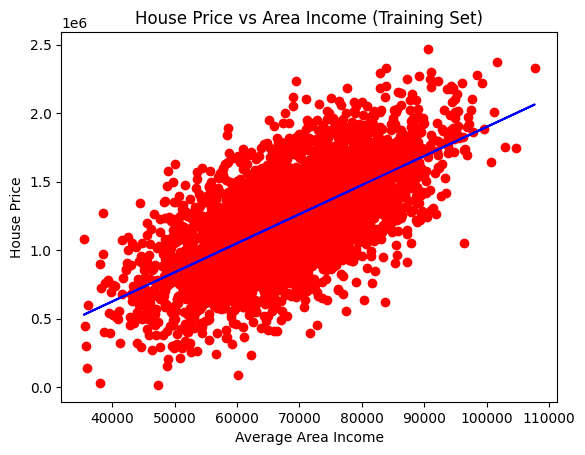

In [ ]:
plt.scatter(X_train, Y_train, color="red")
plt.plot(X_train, regressor.predict(X_train), color="blue")
plt.title("House Price vs Area Income (Training Set)")
plt.xlabel("Average Area Income")
plt.ylabel("House Price")
plt.show()


# Polynomial Regression

In [ ]:
from sklearn.preprocessing import PolynomialFeatures
poly_reg= PolynomialFeatures (degree=2)
X_poly = poly_reg.fit_transform(X_train)
X_test_poly = poly_reg.transform(X_test)


NameError: name 'X_train' is not defined

In [ ]:
from sklearn.linear_model import LinearRegression
lin_reg_2= LinearRegression()
lin_reg_2.fit(X_poly, Y_train)

LinearRegression()

In [ ]:
y_pred = lin_reg_2.predict(X_test_poly)

In [ ]:
from sklearn.metrics import r2_score
print(r2_score(Y_test, y_pred))

0.40182790509742194


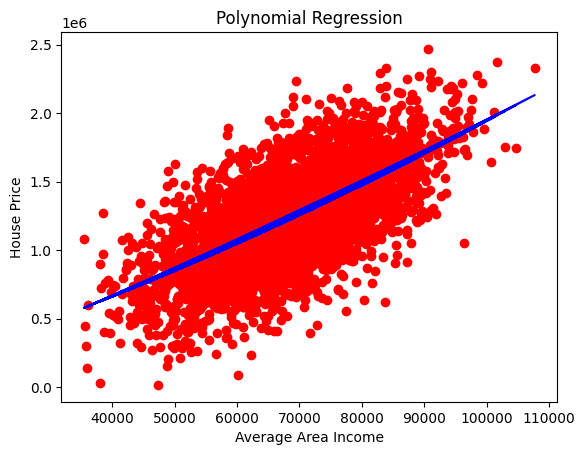

In [ ]:
plt.scatter(X_train, Y_train, color="red")
plt.plot(X_train, lin_reg_2.predict(X_poly), color="blue")
plt.xlabel('Average Area Income')
plt.ylabel('House Price')
plt.title("Polynomial Regression")
plt.show()

# Multi-Linear Regression

In [6]:
X = dataset.iloc[:, :-2].values
Y = dataset.iloc[:, -1].values

In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=0
)

In [8]:
from sklearn.linear_model import LinearRegression

regressor = LinearRegression()

regressor.fit(X_train, Y_train)

LinearRegression()

In [9]:
Y_pred = regressor.predict(X_test)

print(Y_pred)

[ 872025.23411067  901240.27001298 1068091.66384716  625634.37336216
  803029.29032798 1023933.28412852  795375.00202819 1046069.69157353
 1670558.40097063 1603142.76123299 1108449.4590634   969136.290799
 1902626.65369777 1034017.68803425 1173121.91510945  889112.83574428
 1182523.43004352  619609.58517468 1350401.72764154 1553040.14203117
 1167731.54988054 1239605.75563411 1481998.34973667 1151802.42593592
 1250983.81928187  965496.91367295 1264404.31331577 1394202.5800258
 1623308.05905227 1179758.92522594 1455968.17390352 1620334.54856152
  930862.14963493 1271265.3970227  1175908.88598697  861958.84568481
 1121499.14426292 1434300.66884099 1285396.12465583 1355494.85905559
 1649956.26888339  730322.86308956 1141778.44674585 1017212.60300101
 1068857.87371991 1349089.62331007 1058482.36599066 1458598.39067953
 1393981.78608585 1434420.18148475 1049957.61653566 1661100.62479635
 1528135.88381877 1455924.8812103  1217881.01284872  662763.52586244
 1135146.68370743 1247275.80727508 10

In [10]:
from sklearn.metrics import r2_score

print("Multiple Linear Regression R2 Score:",
      r2_score(Y_test, Y_pred))

Multiple Linear Regression R2 Score: 0.7340311574215135


In [11]:
print("Coefficients:", regressor.coef_)

print("Intercept:", regressor.intercept_)

Coefficients: [ 2.14512807e+01  1.62412563e+05  1.22348471e+05 -2.05492797e+03]
Intercept: -2055648.8327335312


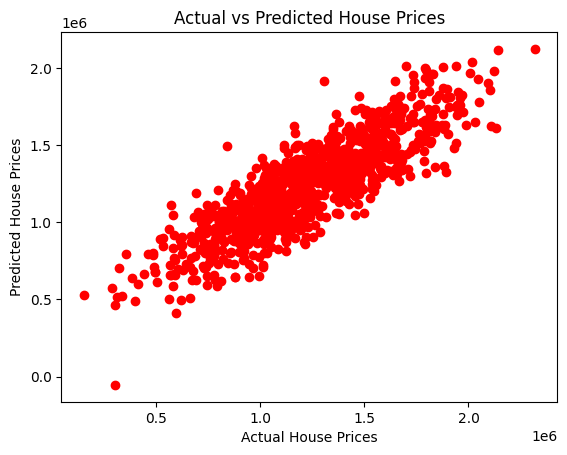

In [12]:
plt.scatter(Y_test, Y_pred, color="red")

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")

plt.title("Actual vs Predicted House Prices")

plt.show()